# Feed-forward network (MLP)

**Final project · Intelligent museum guide** · issue #5

Deliverable 1: a **feed-forward network in PyTorch** that classifies a painting into one of the five styles.
It is built from `nn.Linear` layers and activations (`src/models.py`) and trained with the explicit loop of
`src/train.py` (forward, loss, `zero_grad`, `backward`, `step`), on the shared split of `src/data.py`.

The plan follows the course:

1. **Sanity checks**: the untrained loss is close to ln 5, and the network can learn one batch by heart.
2. **Architecture**: depth, width and activation, compared on the validation set.
3. **Regularisation** (Session 6): weight decay, dropout, data augmentation; early stopping is always on.
4. **Final model**, evaluated **once** on the test set and compared with the baselines (0.37 for a logistic
   regression on the pixels, 0.40 on colour histograms).

With 225 validation images, one run can move by a few points just by changing the seed. Every configuration
is therefore trained with **three seeds**, and we report the mean and the standard deviation.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset

sys.path.append("..")
from src.data import load_splits
from src.models import MLP, count_parameters
from src.plots import plot_history
from src.train import RESULTS_DIR, classification_metrics, evaluate, fit, predict, save_json

np.random.seed(0)
torch.manual_seed(0)
SIZE = 32                      # images downsampled to 32 x 32 pixels
N_IN = 3 * SIZE * SIZE         # 3 072 inputs
LR = 1e-4                      # Adam learning rate (its effect is studied in the monitoring notebook)
loss_fn = nn.CrossEntropyLoss()

## Data

The baseline showed that 16, 32 or 64 pixels give the same accuracy on raw pixels; 32 × 32 keeps some detail
while the first layer stays reasonable (3 072 inputs). The pixels are standardised with the statistics of
the training images. We keep `X_train` to build an augmented loader in Part 3, and a non-shuffled copy of
the training set to measure the train accuracy of a finished model.

In [2]:
splits, classes = load_splits("train", size=SIZE)
X_train, y_train = splits["train"]
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
train_eval_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=256)
val_loader = DataLoader(TensorDataset(*splits["val"]), batch_size=256)
test_loader = DataLoader(TensorDataset(*splits["test"]), batch_size=256)

train 1050 images | per class {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}
val    225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}
test   225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}


## 1. Sanity checks

`MLP(n_in, width, depth)` is `Flatten → [Linear → activation] × depth → Linear(width, 5)`. It returns raw
scores (logits); `nn.CrossEntropyLoss` applies the softmax. Before any training, the five scores are close
to each other, so the loss should be close to ln 5 ≈ 1.61 and the accuracy close to 0.20.

In [3]:
torch.manual_seed(0)
model = MLP(N_IN, width=512, depth=2)
print(model)
print("parameters:", count_parameters(model))
loss0, acc0 = evaluate(model, val_loader, loss_fn)
print(f"untrained: val loss {loss0:.3f} (ln 5 = {np.log(5):.3f}), val accuracy {acc0:.3f}")

MLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=5, bias=True)
  )
)
parameters: 1838597
untrained: val loss 1.613 (ln 5 = 1.609), val accuracy 0.209


A network that cannot learn 64 images by heart has a bug (or no capacity). We train on a single batch
and check that the training loss goes to zero.

In [4]:
xb, yb = next(iter(train_loader))
one_batch = DataLoader(TensorDataset(xb, yb), batch_size=64)
torch.manual_seed(0)
model = MLP(N_IN, width=512, depth=2)
history = fit(model, one_batch, one_batch, loss_fn, torch.optim.Adam(model.parameters(), lr=1e-3),
              n_epochs=100, verbose=False)
print(f"one batch of 64 images, 100 steps: train accuracy {history['train_acc'][-1]:.2f}, "
      f"train loss {history['train_loss'][-1]:.4f}")

one batch of 64 images, 100 steps: train accuracy 1.00, train loss 0.0000


## 2. Architecture

`run` trains one configuration with three seeds (each seed changes the initial weights and the order of
the mini-batches). Each run uses Adam, at most 100 epochs and early stopping with a patience of 10 epochs on
the validation loss, so the network is evaluated at its best epoch. We report the validation accuracy (mean
and standard deviation over the seeds), the gap between train and validation accuracy of the final weights
(a measure of overfitting) and the best epoch.

In [5]:
def run(make_model, loader=train_loader, weight_decay=0.0, seeds=(0, 1, 2)):
    """Train one configuration with several seeds and average the results at the best epoch."""
    val_accs, gaps, best_epochs = [], [], []
    for seed in seeds:
        torch.manual_seed(seed)
        model = make_model()
        optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=weight_decay)
        history = fit(model, loader, val_loader, loss_fn, optimizer, n_epochs=100, patience=10,
                      seed=seed, verbose=False)
        _, train_acc = evaluate(model, train_eval_loader, loss_fn)
        _, val_acc = evaluate(model, val_loader, loss_fn)
        val_accs.append(val_acc)
        gaps.append(train_acc - val_acc)
        best_epochs.append(history["best_epoch"])
    return {"val_acc": float(np.mean(val_accs)), "val_acc_std": float(np.std(val_accs)),
            "gap": float(np.mean(gaps)), "best_epoch": float(np.mean(best_epochs))}


def show(name, r, n_params=None):
    params = f"{n_params:>9,d} params" if n_params is not None else ""
    print(f"{name:22s} val acc {r['val_acc']:.3f} ± {r['val_acc_std']:.3f} | train-val gap {r['gap']:.3f} | "
          f"best epoch {r['best_epoch']:5.1f} {params}")

In [6]:
arch_results = {}
for depth in [1, 2, 3]:
    for width in [128, 512]:
        arch_results[(depth, width)] = run(lambda: MLP(N_IN, width=width, depth=depth))
        show(f"depth {depth}, width {width}", arch_results[(depth, width)],
             count_parameters(MLP(N_IN, width=width, depth=depth)))

best_depth, best_width = max(arch_results, key=lambda k: arch_results[k]["val_acc"])
print(f"best: depth {best_depth}, width {best_width}")

depth 1, width 128     val acc 0.363 ± 0.011 | train-val gap 0.285 | best epoch   7.3   393,989 params


depth 1, width 512     val acc 0.356 ± 0.010 | train-val gap 0.279 | best epoch   3.3 1,575,941 params


depth 2, width 128     val acc 0.367 ± 0.021 | train-val gap 0.235 | best epoch   8.7   410,501 params


depth 2, width 512     val acc 0.381 ± 0.015 | train-val gap 0.186 | best epoch   3.3 1,838,597 params


depth 3, width 128     val acc 0.379 ± 0.011 | train-val gap 0.173 | best epoch   9.0   427,013 params


depth 3, width 512     val acc 0.384 ± 0.017 | train-val gap 0.152 | best epoch   3.7 2,101,253 params
best: depth 3, width 512


**What we see.** The six architectures land between 0.36 and 0.38, within one or two standard deviations
of each other. The networks with 512 units reach their best validation loss after 3 or 4 epochs and then only
learn the training set by heart: with 1.6 to 2.1 million weights for 1 050 images, they have far more
capacity than data. We keep the best one, depth 3 and width 512, knowing that its margin is within the noise.

With the best depth and width, we compare three activations (Session 5). The sigmoid and tanh saturate
for large inputs, where their gradient is almost zero; ReLU does not saturate for positive inputs.

In [7]:
activations = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
act_results = {}
for name, act in activations.items():
    act_results[name] = run(lambda: MLP(N_IN, width=best_width, depth=best_depth, activation=act))
    show(name, act_results[name])

best_act = max(act_results, key=lambda k: act_results[k]["val_acc"])
print("best activation:", best_act)

ReLU                   val acc 0.384 ± 0.017 | train-val gap 0.152 | best epoch   3.7 


Tanh                   val acc 0.359 ± 0.002 | train-val gap 0.137 | best epoch   2.7 


Sigmoid                val acc 0.363 ± 0.006 | train-val gap 0.127 | best epoch  17.7 
best activation: ReLU


**What we see.** ReLU is ahead (0.384) of tanh (0.359) and the sigmoid (0.363), by about one and a half
standard deviations. The clearest difference is the speed: the sigmoid network needs about 18 epochs to reach its
best epoch instead of 4, the effect of saturation and small gradients seen in Session 5. We keep ReLU.

## 3. Regularisation

Five variants of the chosen architecture:

- **weight decay** (L2 penalty, added to the gradient by `Adam(weight_decay=1e-3)`), which keeps the weights
  small;
- **dropout** 0.5 after each hidden layer, which switches off half of the units at random during training;
- **data augmentation** with horizontal flips: a mirrored painting keeps its style, so we add the mirror image
  of every training painting (2 100 training images instead of 1 050);
- dropout and flips together.

Early stopping is on in every run.

In [8]:
flip_loader = DataLoader(TensorDataset(torch.cat([X_train, X_train.flip(-1)]), torch.cat([y_train, y_train])),
                         batch_size=64, shuffle=True)
best_cfg = dict(width=best_width, depth=best_depth, activation=activations[best_act])
regularisations = {
    "none": {},
    "weight decay 1e-3": {"weight_decay": 1e-3},
    "dropout 0.5": {"dropout": 0.5},
    "flip": {"flip": True},
    "dropout 0.5 + flip": {"dropout": 0.5, "flip": True},
}
reg_results = {}
for name, reg in regularisations.items():
    reg_results[name] = run(lambda: MLP(N_IN, **best_cfg, dropout=reg.get("dropout", 0.0)),
                            loader=flip_loader if reg.get("flip") else train_loader,
                            weight_decay=reg.get("weight_decay", 0.0))
    show(name, reg_results[name])

best_reg = max(reg_results, key=lambda k: reg_results[k]["val_acc"])
print("best regularisation:", best_reg)

none                   val acc 0.384 ± 0.017 | train-val gap 0.152 | best epoch   3.7 


weight decay 1e-3      val acc 0.379 ± 0.020 | train-val gap 0.153 | best epoch   3.7 


dropout 0.5            val acc 0.372 ± 0.004 | train-val gap 0.184 | best epoch  15.0 


flip                   val acc 0.394 ± 0.006 | train-val gap 0.120 | best epoch   2.3 


dropout 0.5 + flip     val acc 0.382 ± 0.010 | train-val gap 0.147 | best epoch   9.7 
best regularisation: flip


**What we see.** Only the flips help: 0.394 ± 0.006, with the smallest train-validation gap (0.12).
Weight decay changes nothing, because the weights barely move in the 3 or 4 epochs before the best one. Dropout
delays the best epoch (15 instead of 4) without improving it. Regularisation reduces overfitting, but here it
barely moves the validation accuracy. So overfitting is not the only limit: the input is the other one, a vector
of pixels in which the same style can appear anywhere. This diagnosis is the reason to try a convolutional
network.

## 4. Final model and test set

We train the chosen configuration once more (seed 0), plot its learning curves, and evaluate it **once** on
the test set. The weights are saved in `results/mlp.pt` (git-ignored) for the CPU benchmark.

{'size': 32, 'width': 512, 'depth': 3, 'activation': 'ReLU', 'dropout': 0.0, 'weight_decay': 0.0, 'flip': True, 'lr': 0.0001}


stopped after 12 epochs, best epoch 2, 0.9 s


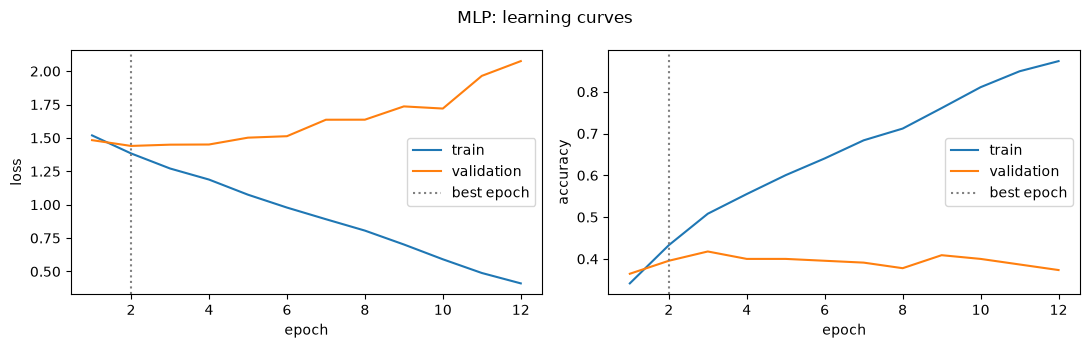

In [9]:
reg = regularisations[best_reg]
config = {"size": SIZE, "width": best_width, "depth": best_depth, "activation": best_act,
          "dropout": reg.get("dropout", 0.0), "weight_decay": reg.get("weight_decay", 0.0),
          "flip": reg.get("flip", False), "lr": LR}
print(config)

torch.manual_seed(0)
model = MLP(N_IN, **best_cfg, dropout=config["dropout"])
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=config["weight_decay"])
history = fit(model, flip_loader if config["flip"] else train_loader, val_loader, loss_fn, optimizer,
              n_epochs=100, patience=10, verbose=False)
print(f"stopped after {len(history['val_loss'])} epochs, best epoch {history['best_epoch']}, "
      f"{history['train_time_s']:.1f} s")
plot_history(history, "MLP: learning curves", RESULTS_DIR / "mlp_curves.png")

MLP test accuracy 0.436, macro-F1 0.415


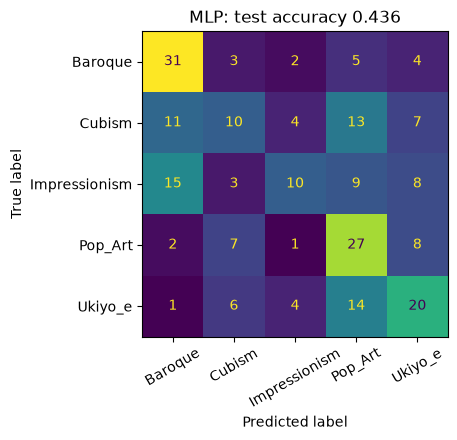

In [10]:
test = classification_metrics(*predict(model, test_loader))
print(f"MLP test accuracy {test['accuracy']:.3f}, macro-F1 {test['macro_f1']:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(np.array(test["confusion_matrix"]), display_labels=classes).plot(ax=ax, colorbar=False)
ax.set_title(f"MLP: test accuracy {test['accuracy']:.3f}")
ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mlp_confusion.png", dpi=120)
plt.show()

torch.save(model.state_dict(), RESULTS_DIR / "mlp.pt")
save_json({
    **test,
    "config": config,
    "n_params": count_parameters(model),
    "train_time_s": history["train_time_s"],
    "best_epoch": history["best_epoch"],
    "history": history,
    "architectures": {f"depth {d}, width {w}": r for (d, w), r in arch_results.items()},
    "activations": act_results,
    "regularisations": reg_results,
}, RESULTS_DIR / "mlp.json")

## What we take from it

- **The MLP reaches 0.436 on the test set** (macro-F1 0.415), above the logistic regressions on pixels (0.369)
  and on colour histograms (0.396). The gaps, 4 to 7 points, are only slightly larger than the standard error
  of about 3 points on 225 images. The test score is also higher than the validation mean (0.39): with so few
  images, a few points between two sets is expected.
- **The learning curves show overfitting.** The validation loss is lowest at epoch 2 and then rises while
  the training accuracy climbs to 0.87. After two epochs the network memorises instead of generalising, and
  early stopping keeps the weights of epoch 2.
- **The errors are those of the baselines.** Baroque (31 / 45) and Pop Art (27 / 45) are recognised by their
  dark tones and saturated colours. Cubism and Impressionism (10 / 45 each) differ by brushwork and shapes, which
  a flattened vector of pixels does not capture. Ukiyo-e is often taken for Pop Art (14 / 45): flat colours
  and outlines.

For the director: on raw pixels, a feed-forward network is only a little better than a logistic regression,
which does not justify a neural network in production. The question is whether a pretrained CNN changes that
(issue #8).